In [269]:
%pip install -r "requirements.txt"


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Creating a split for the posters positioned on Alexanderplatz, Karl-Marx-Allee and Frankfurter Allee  

This notebook pulls all the data from Supabase and creates a buffer based on OSM data to filter entries positioned on Alexanderplatz, Karl-Marx-Allee and Frankfurter Allee for analytical scopes.

### Load and import data from Supabase

In [356]:
import os 
from dotenv import load_dotenv
from supabase import create_client, Client

load_dotenv()

url: str = os.getenv("SUPABASE_URL")
key: str = os.getenv("SUPABASE_KEY")

supabase: Client = create_client(url, key)

In [271]:
first = (
    supabase.table("analyzed_posters")
    .select("*", count="exact")
    .range(0, 0)
    .execute()
)
total = first.count
print("Total rows in table:", total)

Total rows in table: 1485


In [272]:
import pandas as pd

page_size = 1000
rows = []
for start in range(0, total, page_size):
    resp = (
        supabase.table("analyzed_posters")
        .select("*")
        .order("id")  # change to your primary key column
        .range(start, start + page_size - 1)
        .execute()
    )
    print(f"rows {start}-{start + page_size - 1}: got {len(resp.data)}")
    rows.extend(resp.data)

df = pd.DataFrame(rows)
print("Fetched:", len(df))

rows 0-999: got 1000
rows 1000-1999: got 485
Fetched: 1485


In [273]:
df.head(5)

,id,submission_id,box,crop_storage_key,name,slogan,party,dominant_colors,original_result,reviewed,reviewed_at,created_at,categories
0,0046eee4-e140-46ed-a6ee-ef54308264c5,1681c1f4-435c-4c2b-9bec-8994050a6c5e,"{'h': 0.2823624595469256, 'w': 0.3106796116504...",crops/0046eee4-e140-46ed-a6ee-ef54308264c5.jpg,None,Geld für Schulen statt für Waffen! Gefährlich ...,BSW,"[white, orange, magenta, black]","{'name': 'BSW', 'party': 'BSW', 'box_id': '004...",True,2026-08-28T12:54:16.617+00:00,2026-08-22T06:16:22.16918+00:00,"[rearming, school]"
1,00a73197-a931-4f7a-8127-2f7bd79f2090,bb6070dd-91f5-4386-ab11-0981e35c1dac,"{'h': 0.13770341125107052, 'w': 0.158645276292...",crops/00a73197-a931-4f7a-8127-2f7bd79f2090.jpg,None,Wir kämpfen um jeden Arbeitsplatz\nWieder Berl...,SPD,"[red, white]","{'name': None, 'party': 'SPD', 'box_id': '00a7...",True,2026-09-10T20:48:37.518+00:00,2026-08-25T06:22:16.627911+00:00,"[social justice, work]"
2,00ace340-1ce9-4012-a3bc-16176bc92adb,be5d2611-f365-4e5e-b3f2-8eab2b258156,"{'h': 0.2969255663430421, 'w': 0.2750809061488...",crops/00ace340-1ce9-4012-a3bc-16176bc92adb.jpg,None,"SOZIALES, BILDUNG & WOHNEN STATT PROFIT, PANZE...",DKP,"[red, white]","{'name': None, 'party': 'DKP', 'box_id': '00ac...",True,2026-08-18T19:37:15.348+00:00,2026-08-18T18:23:06.810554+00:00,"[education, housing, rearming]"
3,00b44bb9-5464-4bf3-b175-84438a13367e,048ae7d1-7686-4af5-bd51-69aefd764268,"{'h': 0.23705501618122965, 'w': 0.182308522114...",crops/00b44bb9-5464-4bf3-b175-84438a13367e.jpg,None,Berlin bleibt stadt des Friedens\nBerlin bezah...,Die Linke,"[red, blue, white, green]","{'name': None, 'party': 'Die Linke', 'box_id':...",True,2026-08-16T16:14:20.832+00:00,2026-08-15T06:19:25.96562+00:00,"[affordability, peace, war]"
4,00bbfc71-ee73-4bbb-b3c7-45b0cc1c0315,a184cd1f-f7db-4679-ad95-0bc942806de9,"{'h': 0.24676375404530737, 'w': 0.210355987055...",crops/00bbfc71-ee73-4bbb-b3c7-45b0cc1c0315.jpg,KRISTIN BRINKER,BERLIN. STARK. MACHEN.,AfD,"[blue, white, light blue, skin tone, black, red]","{'name': 'KRISTIN BRINKER', 'party': 'AfD', 'b...",True,2026-08-18T19:07:19.247+00:00,2026-08-18T18:20:37.973126+00:00,"[city, power, strength]"


In [274]:
page_size = 1000
rows = []
for start in range(0, total, page_size):
    resp = (
        supabase.table("submissions")
        .select("*")
        .order("id")  # change to your primary key column
        .range(start, start + page_size - 1)
        .execute()
    )
    print(f"rows {start}-{start + page_size - 1}: got {len(resp.data)}")
    rows.extend(resp.data)

df_coordinates = pd.DataFrame(rows)
print("Fetched:", len(df_coordinates))

rows 0-999: got 816
rows 1000-1999: got 0
Fetched: 816


In [275]:
len(df_coordinates)

816

In [276]:
df_geo_posters = df.merge(
    df_coordinates[["id", "latitude","longitude", "accuracy"]], 
    left_on="submission_id",
    right_on="id", 
    how="left",
    suffixes=("", "_submission")
)

In [277]:
len(df_geo_posters)

1485

In [278]:
df_geo_posters["latitude"].isna().sum()

np.int64(0)

### Loads geometry from OSM and creates buffer to filter data

In [279]:
import geopandas
osm = geopandas.read_file("./assets/frankfurter-karl-marx.geojson")
osm

,id,@id,addr:city,addr:floor,addr:housenumber,addr:postcode,addr:street,area,atm,atm:operator,...,vehicle,website,wheelchair,width,wikidata,wikipedia,zone:maxspeed,@relations,zone:traffic,geometry
0,relation/3637412,relation/3637412,None,None,None,None,None,yes,None,None,...,None,None,yes,None,None,None,None,None,None,"POLYGON ((13.41216 52.52094, 13.41223 52.52098..."
1,relation/3637944,relation/3637944,None,None,None,None,None,yes,None,None,...,None,None,limited,None,None,None,None,None,None,"POLYGON ((13.41356 52.52207, 13.41343 52.52213..."
2,relation/11764689,relation/11764689,None,None,None,None,None,yes,None,None,...,None,None,yes,None,None,None,None,None,None,"POLYGON ((13.47476 52.51455, 13.47482 52.51456..."
3,relation/18138769,relation/18138769,None,None,None,None,None,None,None,None,...,None,None,yes,None,None,None,None,None,None,"POLYGON ((13.47614 52.51353, 13.47615 52.51357..."
4,way/48012113,way/48012113,None,None,None,None,None,yes,None,None,...,None,None,yes,None,None,None,None,None,None,"POLYGON ((13.41222 52.52143, 13.41214 52.52138..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458,node/4598414751,node/4598414751,None,None,None,None,None,None,None,None,...,None,https://www.bvg.de/de/verbindungen/stationsueb...,yes,None,None,None,None,None,None,POINT (13.41391 52.52158)
459,node/6403474008,node/6403474008,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,POINT (13.43046 52.51796)
460,node/6403474012,node/6403474012,None,None,None,None,None,None,None,None,...,None,https://www.stalinbauten.de/karl-marx-allee/#/,yes,None,None,None,None,None,None,POINT (13.43168 52.5185)
461,node/6403474014,node/6403474014,None,None,None,None,None,None,None,None,...,None,https://www.stalinbauten.de/karl-marx-allee/#/,None,None,None,None,None,None,None,POINT (13.43048 52.51863)


In [357]:
# Retains entities that match the names of the streets
street_names = ["Frankfurter Allee", "Karl-Marx-Allee", "Tunnel Alexanderplatz"]
# Keeps only LineStrings to remove other elements like nodes and relations
frankfurter_boundaries = osm[osm["name"].isin(street_names) & (osm.geom_type == "LineString")].to_crs("EPSG:25833")
frankfurter_boundaries["name"].value_counts()

name
Frankfurter Allee        173
Karl-Marx-Allee           71
Tunnel Alexanderplatz     11
Name: count, dtype: int64

In [358]:
# Alex is treated as separate entity because it is a multipolygon. I use OSM entity name to isolate it
alex = osm[(osm["name"] == "Alexanderplatz") & (osm["place"] == "square")].to_crs("EPSG:25833")
len(alex)  # should be 1

1

In [ ]:
# Concatenate the different shapes together 
shapes = geopandas.GeoSeries(
    pd.concat([frankfurter_boundaries.geometry, alex.geometry]), crs="EPSG:25833"
)

<Axes: >

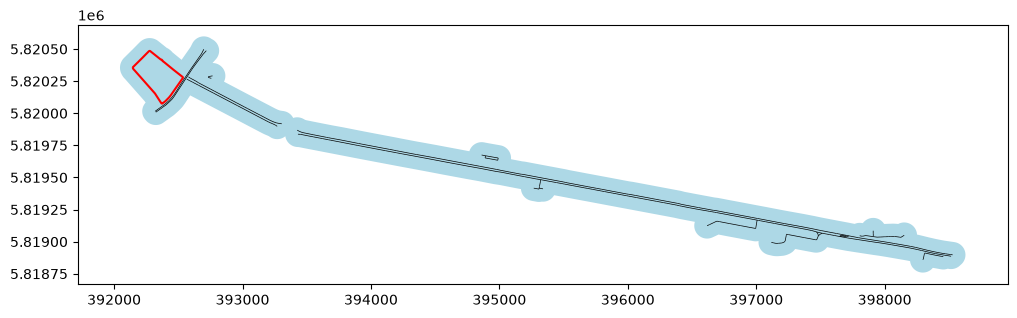

In [ ]:
# Creates unique shape with a buffer of 100 meters to capture all posters (this is quite large, but I know the data well and I would rather stay a bit broad than risk on missing some data)
zone = geopandas.GeoDataFrame(geometry=[shapes.buffer(100).union_all()], crs="EPSG:25833")

ax = zone.plot(color="lightblue", figsize=(12, 4))
frankfurter_boundaries.plot(ax=ax, color="black", linewidth=0.5)
alex.boundary.plot(ax=ax, color="red")

In [369]:
# Extract coordinates for the posters and convert them into Points
gdf = geopandas.GeoDataFrame(
    df_geo_posters, geometry=geopandas.points_from_xy(df_geo_posters.longitude, df_geo_posters.latitude), crs="EPSG:4326"
)

<Axes: >

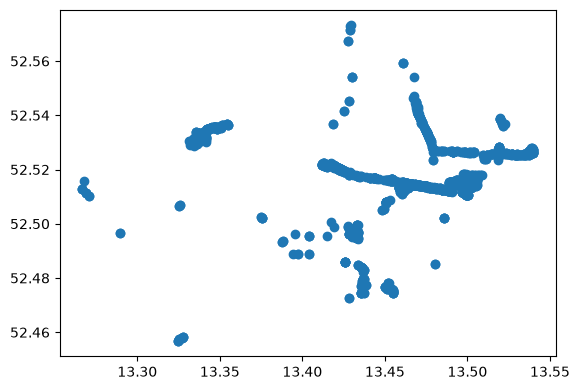

In [370]:
gdf.plot()

In [371]:
gdf = gdf.to_crs("EPSG:25833")

In [372]:
gdf.geometry.head()

0    POINT (392365.674 5820197.725)
1       POINT (393793.36 5815353.9)
2    POINT (395056.259 5819553.526)
3     POINT (400905.01 5820673.252)
4      POINT (396378.56 5821917.62)
Name: geometry, dtype: geometry

### Filter poster data that are only within the buffer around the street

In [373]:
# Filters posters that are within the buffer
frankfurter_posters = gdf.sjoin(zone, predicate="within")
print(len(frankfurter_posters), frankfurter_posters["id"].duplicated().sum())

568 0


### Loads Wahlbezirke data

In [422]:
voting_areas = geopandas.read_file("./assets/wahlbezirke_2026.geojson")

In [423]:
voting_areas.head()

,UWB,UWB3,BWB,BWB3,AWK,BEZ,BWK,geometry
0,01127,127,011S,1S,0101,01,74,"MULTIPOLYGON (((390976.766 5820924.441, 390977..."
1,01207,207,012C,2C,0102,01,74,"MULTIPOLYGON (((391049.196 5820366.165, 391082..."
2,01230,230,012N,2N,0102,01,74,"MULTIPOLYGON (((392987.259 5818586.138, 392810..."
3,01301,301,013A,3A,0103,01,74,"MULTIPOLYGON (((386362.776 5821062.39, 386329...."
4,01303,303,013B,3B,0103,01,74,"MULTIPOLYGON (((386748.092 5820985.664, 386716..."


In [377]:
voting_areas = voting_areas[["UWB", "AWK", "geometry"]]

In [378]:
frankfurter_posters = frankfurter_posters.drop(columns={"index_right"})

In [379]:
f_posters_by_area = frankfurter_posters.sjoin(voting_areas, predicate="within")

In [424]:
print("Original filter:", len(frankfurter_posters))
print("Check against Wahlbezirke filter:", len(f_posters_by_area))

Original filter: 568
Check against Wahlbezirke filter: 568


In [382]:
f_posters_by_area["UWB"].value_counts().describe()

count    27.000000
mean     21.037037
std      16.851116
min       1.000000
25%       9.000000
50%      16.000000
75%      27.000000
max      74.000000
Name: count, dtype: float64

In [383]:
f_posters_by_area["AWK"].value_counts().describe()

count      5.000000
mean     113.600000
std       70.109201
min       17.000000
25%       67.000000
50%      132.000000
75%      172.000000
max      180.000000
Name: count, dtype: float64

### Creation of reference line to split posters along the street

In [384]:
frankfurter_boundaries = frankfurter_boundaries[frankfurter_boundaries["highway"] == "primary"]

In [ ]:
coordinates_street = frankfurter_boundaries.get_coordinates()
coordinates_street["slice"] = coordinates_street["x"] // 100
centre = coordinates_street.groupby("slice")[["x", "y"]].mean().sort_values("x")

In [390]:
from shapely import LineString
ref_line = LineString(centre.values)

In [391]:
print((ref_line.length), "m")

6503.60043454674 m


<Axes: >

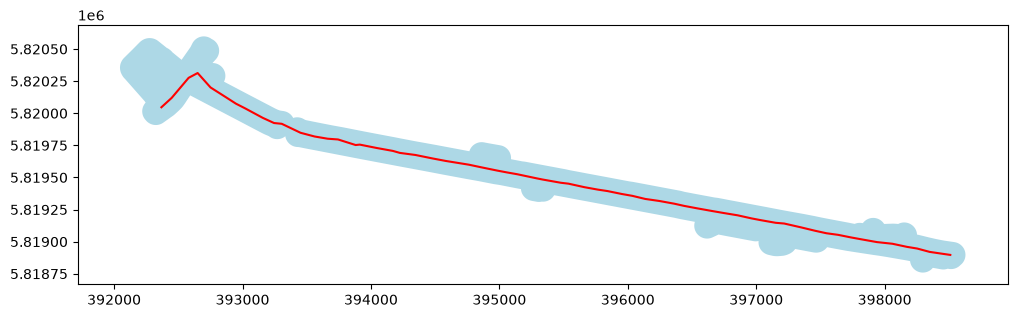

In [392]:
ax = zone.plot(color="lightblue", figsize=(12, 4))
geopandas.GeoSeries([ref_line], crs="EPSG:25833").plot(ax=ax, color="red")

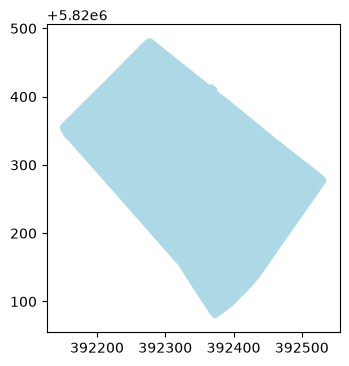

In [393]:
ax = alex.geometry.plot(color="lightblue", figsize=(12, 4))


In [394]:
alex_buffer = alex.geometry.buffer(20)

<Axes: >

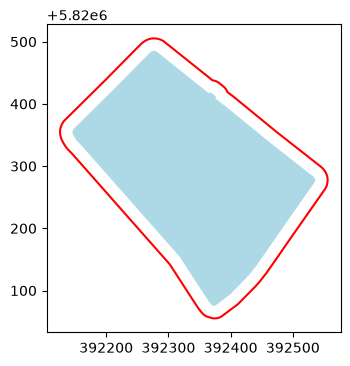

In [395]:
ax = alex.geometry.plot(color="lightblue", figsize=(12, 4))
alex_buffer.boundary.plot(ax=ax, color="red")

In [396]:
alex_buffer_shape = alex_buffer.union_all()

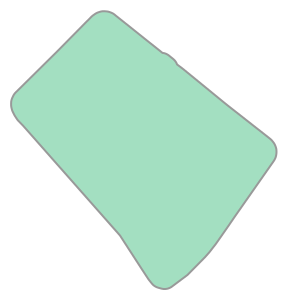

In [397]:
alex_buffer_shape

In [398]:
is_alex = f_posters_by_area.within(alex_buffer_shape)

In [399]:
is_alex

0        True
2       False
6       False
8       False
11      False
        ...  
1475    False
1479     True
1481    False
1483    False
1484     True
Length: 568, dtype: bool

### Assign posters to each stretch of street

In [400]:
f_posters_by_area["on_alex"] = is_alex

In [401]:
f_posters_by_area[f_posters_by_area["on_alex"] == True]

,id,submission_id,box,crop_storage_key,name,slogan,party,dominant_colors,original_result,reviewed,...,categories,id_submission,latitude,longitude,accuracy,geometry,index_right,UWB,AWK,on_alex
0,0046eee4-e140-46ed-a6ee-ef54308264c5,1681c1f4-435c-4c2b-9bec-8994050a6c5e,"{'h': 0.2823624595469256, 'w': 0.3106796116504...",crops/0046eee4-e140-46ed-a6ee-ef54308264c5.jpg,None,Geld für Schulen statt für Waffen! Gefährlich ...,BSW,"[white, orange, magenta, black]","{'name': 'BSW', 'party': 'BSW', 'box_id': '004...",True,...,"[rearming, school]",1681c1f4-435c-4c2b-9bec-8994050a6c5e,52.521245,13.413599,17.665217,POINT (392365.674 5820197.725),1973,01205,0102,True
18,031030fe-d946-4d34-bba1-18691acf99e8,72f08e61-9fe6-4623-9b52-bf3bd752be2c,"{'h': 0.21763754045307432, 'w': 0.220064724919...",crops/031030fe-d946-4d34-bba1-18691acf99e8.jpg,Christoph Keller,Bezirksbürgermeister für Mitte,Die Linke,"[red, white, purple]","{'name': 'Christoph Keller', 'party': 'Die Lin...",True,...,[candidate],72f08e61-9fe6-4623-9b52-bf3bd752be2c,52.521620,13.412976,49.418286,POINT (392324.374 5820240.402),1973,01205,0102,True
21,038864a7-e454-4ac7-8570-479771175a8f,5d6b8af9-3866-4bbd-ac37-db71a74665e4,"{'h': 0.168284789644013, 'w': 0.20496224379719...",crops/038864a7-e454-4ac7-8570-479771175a8f.jpg,None,MIGRATION BRAUCHT GRENZEN.,AfD,"[blue, white, red]","{'name': 'AfD', 'party': 'AfD', 'box_id': '038...",True,...,[migration],5d6b8af9-3866-4bbd-ac37-db71a74665e4,52.521336,13.413845,42.386777,POINT (392382.638 5820207.522),1973,01205,0102,True
24,04161d01-30d0-489f-a86f-8309cf3abb67,7bda0493-0a3a-4670-9b6b-e3201dfcb7e1,"{'h': 0.20307443365695801, 'w': 0.213592233009...",crops/04161d01-30d0-489f-a86f-8309cf3abb67.jpg,None,DAMIT\nBERLIN\nFUNKTIONIERT.,AfD,"[blue, white, red]","{'name': None, 'party': 'AfD', 'box_id': '0416...",True,...,[administration],7bda0493-0a3a-4670-9b6b-e3201dfcb7e1,52.521884,13.412204,13.999999,POINT (392272.614 5820270.96),1973,01205,0102,True
42,05bc6adf-481e-4644-837d-604e27e4ab1c,c15d4613-1ecd-42f3-9bcb-3966abc654da,"{'h': 0.2831715210355986, 'w': 0.2793959007551...",crops/05bc6adf-481e-4644-837d-604e27e4ab1c.jpg,Elif Eralp,Bürgermeisterin für Berlin,Die Linke,"[red, white, black]","{'name': 'Elif Eralp', 'party': 'Die Linke', '...",True,...,[mayor],c15d4613-1ecd-42f3-9bcb-3966abc654da,52.521369,13.415384,9.773295,POINT (392487.11 5820208.905),1973,01205,0102,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1329,e3d04399-9373-461d-a7af-0070ded490ff,337ba6c7-3cb7-4fb4-8e1a-fcf0788178b8,"{'h': 0.27427184466019416, 'w': 0.249190938511...",crops/e3d04399-9373-461d-a7af-0070ded490ff.jpg,None,Weniger Washington. Mehr Deutschland. Gefährli...,BSW,"[black, red, gold, white]","{'name': None, 'party': 'BSW Bündnis Sahra Wag...",True,...,"[freedom, sovereignity]",337ba6c7-3cb7-4fb4-8e1a-fcf0788178b8,52.521228,13.414454,28.907080,POINT (392423.68 5820194.606),1973,01205,0102,True
1389,f032ec78-436d-456e-8b49-4697423d3dd9,67508551-400a-4b14-887c-58d1f43f3a7d,"{'h': 0.18042071197411014, 'w': 0.159654800431...",crops/f032ec78-436d-456e-8b49-4697423d3dd9.jpg,None,Mietabzocke stoppen\nBerlin bezahlbar machen,Die Linke,"[red, purple, white]","{'name': None, 'party': 'Die Linke', 'box_id':...",True,...,"[affordability, housing, rent]",67508551-400a-4b14-887c-58d1f43f3a7d,52.521298,13.413722,30.081487,POINT (392374.201 5820203.455),1973,01205,0102,True
1461,fd4a3afb-130c-43e6-8b82-2bb552283aee,d7a4a82f-6cd2-40cb-8d98-a88b436e351c,"{'h': 0.2297734627831714, 'w': 0.2157497303128...",crops/fd4a3afb-130c-43e6-8b82-2bb552283aee.jpg,None,ENDLICH EINE SCHMUTZ-KAMPAGNE. Zusammen gegen ...,Volt,"[purple, white, green]","{'name': None, 'party': 'Volt', 'box_id': 'fd4...",True,...,"[kiez, trash]",d7a4a82f-6cd2-40cb-8d98-a88b436e351c,52.521320,13.414427,59.856308,POINT (392422.084 5820204.933),1973,01205,0102,True
1479,ff46c714-de76-446b-921a-def671a5a577,47dd9a2c-3df8-4e02-805f-95a0ac5b2792,"{'h': 0.19012944983818808, 'w':

In [402]:
from shapely import line_locate_point

In [403]:
f_posters_by_area

,id,submission_id,box,crop_storage_key,name,slogan,party,dominant_colors,original_result,reviewed,...,categories,id_submission,latitude,longitude,accuracy,geometry,index_right,UWB,AWK,on_alex
0,0046eee4-e140-46ed-a6ee-ef54308264c5,1681c1f4-435c-4c2b-9bec-8994050a6c5e,"{'h': 0.2823624595469256, 'w': 0.3106796116504...",crops/0046eee4-e140-46ed-a6ee-ef54308264c5.jpg,None,Geld für Schulen statt für Waffen! Gefährlich ...,BSW,"[white, orange, magenta, black]","{'name': 'BSW', 'party': 'BSW', 'box_id': '004...",True,...,"[rearming, school]",1681c1f4-435c-4c2b-9bec-8994050a6c5e,52.521245,13.413599,17.665217,POINT (392365.674 5820197.725),1973,01205,0102,True
2,00ace340-1ce9-4012-a3bc-16176bc92adb,be5d2611-f365-4e5e-b3f2-8eab2b258156,"{'h': 0.2969255663430421, 'w': 0.2750809061488...",crops/00ace340-1ce9-4012-a3bc-16176bc92adb.jpg,None,"SOZIALES, BILDUNG & WOHNEN STATT PROFIT, PANZE...",DKP,"[red, white]","{'name': None, 'party': 'DKP', 'box_id': '00ac...",True,...,"[education, housing, rearming]",be5d2611-f365-4e5e-b3f2-8eab2b258156,52.515980,13.453442,4.915418,POINT (395056.259 5819553.526),2110,02420,0204,False
6,01935f5c-4fe5-4a19-bfb5-5fa0d073c69c,6ce434d4-47d4-4203-ab9a-eded48e08087,"{'h': 0.18527508090614864, 'w': 0.179072276159...",crops/01935f5c-4fe5-4a19-bfb5-5fa0d073c69c.jpg,Steffen Krach,Der nächste Regierende,SPD,"[blue, gray, white, green]","{'name': 'STEFFEN KRACH', 'party': 'SPD', 'box...",True,...,[mayor],6ce434d4-47d4-4203-ab9a-eded48e08087,52.513849,13.472106,38.906767,POINT (396317.606 5819289.564),2146,02530,0205,False
8,01b5dd7e-0768-47a4-9512-b64875549880,b25714e1-fe6b-4adc-9ccb-19f06902b524,"{'h': 0.3875404530744335, 'w': 0.4066882416396...",crops/01b5dd7e-0768-47a4-9512-b64875549880.jpg,Lucas Schaal,Berlin wird. Einer für alle Nachbarn.,CDU,"[turquoise, black, white, magenta]","{'name': 'Lucas Schaal', 'party': 'CDU', 'box_...",True,...,"[candidate, provenance (of candidate)]",b25714e1-fe6b-4adc-9ccb-19f06902b524,52.520728,13.419258,20.833925,POINT (392748.374 5820131.849),1435,01212,0102,False
11,01fd81b8-e853-44b4-87e8-d1669e647fd5,cb6eab17-8b5b-40e1-9f38-ea95234458ca,"{'h': 0.14482200647249183, 'w': 0.161812297734...",crops/01fd81b8-e853-44b4-87e8-d1669e647fd5.jpg,None,WOHNUNGEN FÜR BERLINER.,AfD,"[blue, white, red]","{'name': 'AfD', 'party': 'AfD', 'box_id': '01f...",True,...,[housing],cb6eab17-8b5b-40e1-9f38-ea95234458ca,52.514055,13.472540,21.952543,POINT (396347.574 5819311.815),2145,02516,0205,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1475,fecbf266-0509-4d77-ae4a-551f477416e7,6f66ed63-3e48-47db-861d-00f21f854043,"{'h': 0.17961165048543687, 'w': 0.208198489751...",crops/fecbf266-0509-4d77-ae4a-551f477416e7.jpg,Tamara LÜDKE,WIEDER BERLIN MIT STEFFEN KRACH,SPD,"[red, white, black]","{'name': 'Tamara LÜDKE', 'party': 'SPD BERLIN'...",True,...,"[candidate, mayor]",6f66ed63-3e48-47db-861d-00f21f854043,52.513279,13.477475,6.689509,POINT (396680.614 5819218.449),762,11429,1104,False
1479,ff46c714-de76-446b-921a-def671a5a577,47dd9a2c-3df8-4e02-805f-95a0ac5b2792,"{'h': 0.19012944983818808, 'w': 0.238403451995...",crops/ff46c714-de76-446b-921a-def671a5a577.jpg,JULIAN ADRAT,BERLIN. STARK. MACHEN.,AfD,"[blue, white, red]","{'name': 'JULIAN ADRAT', 'party': 'AfD', 'box_...",True,...,"[city, power, strength]",47dd9a2c-3df8-4e02-805f-95a0ac5b2792,52.522270,13.412745,78.892442,POINT (392310.276 5820313.1),1973,01205,0102,True
1481,ff5dbede-375d-467d-ab70-cc5e53bf1bec,9c8f4034-6eb5-4a0d-92cb-90a85353973d,"{'h': 0.1771844660194174, 'w': 0.1779935275080...",crops/ff5dbede-375d-467d-ab70-cc5e53bf1bec.jpg,None,unf*ck berlin,Volt,"[yellow, purple, black]","{'name': None, 'party': 'Volt', 'box_id': 'ff5...",True,...,[administration],9c8f4034-6eb5-4a0d-92cb-90a85353973d,52.511902,13.497186,20.724722,POINT (398014.946 5819037.269),761,11428,1104,False
1483,ff720b6d-07c6-4768-9d9b-133e0702964f,e7ac7303-5363-437e-bbac-b093d63eaf6f,"{'h': 0.19907407407407407, 'w': 0.194444444444

In [404]:
f_posters_by_area["dist_m"] = line_locate_point(ref_line, f_posters_by_area["geometry"])

In [405]:
f_posters_by_area["dist_m"].describe()

count     568.000000
mean     3021.150217
std      1935.622975
min        72.825176
25%       827.095574
50%      3516.445447
75%      4548.616604
max      6203.070034
Name: dist_m, dtype: float64

In [406]:
#find edges of Alex
alex_coords = alex_buffer.get_coordinates()
alex_coords = geopandas.points_from_xy(alex_coords["x"], alex_coords["y"])
distance_from_alex = line_locate_point(ref_line, alex_coords)
max_dist_from_alex = distance_from_alex.max()

In [407]:
max_dist_from_alex

np.float64(315.90282891568927)

In [ ]:
import numpy as np
# set all posters on alex as nan in dist. They will be treated as a separated stretch.
f_posters_by_area.loc[f_posters_by_area["on_alex"] == True, ["dist_m"]] = np.nan
f_posters_by_area["dist_m"].isna().sum()


In [ ]:
# Calculate the distance from Alex for each poster based on its edge
f_posters_by_area["dist_from_alex"] = f_posters_by_area["dist_m"] - max_dist_from_alex

In [ ]:
# Set negative values (due to GPS accuracy) to 0 – because they are at the border with Alex
f_posters_by_area["dist_from_alex"] = f_posters_by_area["dist_from_alex"].clip(lower=0, upper=f_posters_by_area["dist_from_alex"].max())
f_posters_by_area["dist_from_alex"].min()

In [414]:
f_posters_by_area["stretch"] = f_posters_by_area["dist_from_alex"] // 500

In [415]:
f_posters_by_area["stretch"] = f_posters_by_area["stretch"].astype("Int64")

In [416]:
poster_by_stretch = f_posters_by_area["stretch"].value_counts().sort_index()

In [418]:
poster_by_stretch = poster_by_stretch.reset_index()
poster_by_stretch = poster_by_stretch.drop(columns={"index"})
poster_by_stretch

,stretch,count
0,0,73
1,1,45
2,2,12
3,3,13
4,4,14
5,5,42
6,6,58
7,7,80
8,8,57
9,9,55


In [419]:
tot_alex = len(f_posters_by_area[f_posters_by_area["on_alex"] == True])
tot_alex


61

In [420]:
posters_on_alex = pd.DataFrame([[-1, tot_alex]], columns=["stretch", "count"])
posters_on_alex

,stretch,count
0,-1,61


In [421]:
count_of_posters = pd.concat([poster_by_stretch, posters_on_alex], ignore_index=True)
count_of_posters

,stretch,count
0,0,73
1,1,45
2,2,12
3,3,13
4,4,14
5,5,42
6,6,58
7,7,80
8,8,57
9,9,55


In [432]:
import altair as alt
alt.renderers.enable("html")
street_end_m = f_posters_by_area["dist_from_alex"].max()   # ≈ 5733 m

chart_data = count_of_posters.sort_values("stretch").copy()

# Readable labels: "Alex", "0–0.5 km", ... last one marked as shorter
def make_label(s):
    if s == -1:
        return "Alex"
    start = s * 0.5
    end = start + 0.5
    if end * 1000 > street_end_m:
        return f"{start:g}–{street_end_m/1000:.1f} km*"
    return f"{start:g}–{end:g} km"

chart_data["label"] = chart_data["stretch"].apply(make_label)
chart_data["kind"] = "Street (500 m stretch)"
chart_data.loc[chart_data["stretch"] == -1, "kind"] = "Alexanderplatz (square)"

order = chart_data["label"].tolist()   # keeps the ride order, not alphabetical

chart = alt.Chart(chart_data).mark_bar().encode(
    x=alt.X("label:O", sort=order, title="Distance from Alexanderplatz",
            axis=alt.Axis(labelAngle=-40)),
    y=alt.Y("count:Q", title="Posters", axis=alt.Axis()),
    color=alt.Color("kind:N", title=None,
        scale=alt.Scale(domain=["Alexanderplatz (square)", "Street (500 m stretch)"],
                        range=["#C21F1F", "#3A6FB0"]),
        legend=alt.Legend(orient="top")),
    tooltip=[alt.Tooltip("label:N", title="Section"),
             alt.Tooltip("count:Q", title="Posters")],
).properties(
    width=600, height=280,
    title=alt.Title("Election posters along Karl-Marx-Allee / Frankfurter Allee",
                    subtitle="* last stretch is only ~230 m long")
).configure_view(stroke=None)

chart

alt.Chart(...)